In [3]:
import os, glob, time, json, shutil, subprocess, zipfile
import numpy as np
import pandas as pd

CONFIG = dict(
    drive_dir     = "/content/drive/MyDrive/acn_project",
    local_dir     = "/content/acn_project",
    zip_name      = "MERGED_CSV.zip",
    parquet_dir   = "/content/acn_project/parquet",
    csv_dir       = "/content/acn_project/csv",
    sample_frac   = 0.05,   # 0.05 ≈ 2.3M rows; use 0.10 if RAM/time allows
    test_size     = 0.30,   # 15% val + 15% test after inner split
    target        = "binary",   # "binary" or "multi"
    seed          = 42,
    smoke         = False,  # True = tiny run just to verify pipeline
)

for k in ("local_dir", "parquet_dir", "csv_dir"):
    os.makedirs(CONFIG[k], exist_ok=True)

GPU = subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
print("GPU available:", GPU)

GPU available: True


In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
src = os.path.join(CONFIG["drive_dir"], CONFIG["zip_name"])
assert os.path.exists(src), f"Not found: {src}"

local_zip = "/content/MERGED_CSV.zip"
if not os.path.exists(local_zip):
    print("Copying zip to local disk...")
    shutil.copy(src, local_zip)

print("Extracting...")
with zipfile.ZipFile(local_zip) as z:
    z.extractall(CONFIG["csv_dir"])

csv_files = sorted(glob.glob(f'{CONFIG["csv_dir"]}/**/*.csv', recursive=True))
print(f"{len(csv_files)} CSV files found")
for f in csv_files[:5]:
    print(" ", os.path.relpath(f, CONFIG["csv_dir"]), f"{os.path.getsize(f)/1e6:.1f} MB")

Copying zip to local disk...
Extracting...
63 CSV files found
  MERGED_CSV/Merged01.csv 147.1 MB
  MERGED_CSV/Merged02.csv 154.6 MB
  MERGED_CSV/Merged03.csv 144.1 MB
  MERGED_CSV/Merged04.csv 139.8 MB
  MERGED_CSV/Merged05.csv 153.9 MB


In [6]:
import pyarrow as pa
import pyarrow.parquet as pq

def convert_csv_to_parquet(csv_path, out_path, chunksize=1_000_000):
    writer = None
    n_rows = 0
    for chunk in pd.read_csv(csv_path, chunksize=chunksize, low_memory=False):
        chunk = chunk.drop(columns=[c for c in chunk.columns if str(c).startswith("Unnamed")],
                           errors="ignore")
        # downcast features
        for c in chunk.columns:
            if c == "Label":
                continue
            if pd.api.types.is_integer_dtype(chunk[c]):
                chunk[c] = pd.to_numeric(chunk[c], downcast="integer")
            elif pd.api.types.is_float_dtype(chunk[c]):
                chunk[c] = chunk[c].astype("float32")
        # keep Label as string (avoids dictionary-schema mismatch across chunks)
        if "Label" in chunk.columns:
            chunk["Label"] = chunk["Label"].astype(str)
        tbl = pa.Table.from_pandas(chunk, preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(out_path, tbl.schema, compression="snappy")
        writer.write_table(tbl)
        n_rows += len(chunk)
    if writer:
        writer.close()
    return n_rows

t0 = time.time()
for i, f in enumerate(csv_files, 1):
    out = os.path.join(CONFIG["parquet_dir"],
                       os.path.splitext(os.path.basename(f))[0] + ".parquet")
    if os.path.exists(out):
        print(f"[{i}/{len(csv_files)}] skip (exists): {os.path.basename(out)}")
        continue
    n = convert_csv_to_parquet(f, out)
    print(f"[{i}/{len(csv_files)}] {os.path.basename(f)} -> {n:,} rows  "
          f"({time.time()-t0:.0f}s elapsed)")
print("Done.")

[1/63] Merged01.csv -> 712,311 rows  (4s elapsed)
[2/63] Merged02.csv -> 748,585 rows  (9s elapsed)
[3/63] Merged03.csv -> 697,289 rows  (13s elapsed)
[4/63] Merged04.csv -> 676,620 rows  (17s elapsed)
[5/63] Merged05.csv -> 744,804 rows  (22s elapsed)
[6/63] Merged06.csv -> 718,229 rows  (26s elapsed)
[7/63] Merged07.csv -> 702,212 rows  (30s elapsed)
[8/63] Merged08.csv -> 712,220 rows  (35s elapsed)
[9/63] Merged09.csv -> 678,882 rows  (39s elapsed)
[10/63] Merged10.csv -> 916,190 rows  (44s elapsed)
[11/63] Merged11.csv -> 909,761 rows  (50s elapsed)
[12/63] Merged12.csv -> 896,941 rows  (55s elapsed)
[13/63] Merged13.csv -> 709,937 rows  (59s elapsed)
[14/63] Merged14.csv -> 902,920 rows  (65s elapsed)
[15/63] Merged15.csv -> 718,483 rows  (69s elapsed)
[16/63] Merged16.csv -> 765,369 rows  (74s elapsed)
[17/63] Merged17.csv -> 731,532 rows  (78s elapsed)
[18/63] Merged18.csv -> 714,063 rows  (83s elapsed)
[19/63] Merged19.csv -> 701,978 rows  (87s elapsed)
[20/63] Merged20.csv ->

In [7]:
import pyarrow.dataset as ds

dset = ds.dataset(CONFIG["parquet_dir"], format="parquet")
print("Total rows:", f"{dset.count_rows():,}")
print("Schema:")
print(dset.schema)

# First file: shape + dtypes
first = sorted(glob.glob(f'{CONFIG["parquet_dir"]}/*.parquet'))[0]
df0 = pq.read_table(first).to_pandas()
print("\nFirst file:", os.path.basename(first))
print("shape:", df0.shape)
print("columns:", df0.columns.tolist())
print("\ndtypes:\n", df0.dtypes)
print("\nmemory (MB):", df0.memory_usage(deep=True).sum()/1024**2)

# Global label counts (streamed — only reads Label column)
counts = {}
for batch in dset.to_batches(columns=["Label"], batch_size=1_000_000):
    vc = batch.column("Label").to_pandas().value_counts()
    for k, v in vc.items():
        counts[k] = counts.get(k, 0) + int(v)
label_counts = pd.Series(counts).sort_values(ascending=False)
print("\nGlobal Label counts:")
print(label_counts.to_string())

Total rows: 45,019,243
Schema:
Header_Length: float
Protocol Type: int8
Time_To_Live: float
Rate: float
fin_flag_number: float
syn_flag_number: float
rst_flag_number: float
psh_flag_number: float
ack_flag_number: float
ece_flag_number: float
cwr_flag_number: float
ack_count: int8
syn_count: int8
fin_count: int8
rst_count: int8
HTTP: float
HTTPS: float
DNS: float
Telnet: float
SMTP: float
SSH: float
IRC: float
TCP: float
UDP: float
DHCP: float
ARP: float
ICMP: float
IGMP: float
IPv: float
LLC: float
Tot sum: int32
Min: int16
Max: int16
AVG: float
Std: float
Tot size: float
IAT: float
Number: int8
Variance: float
Label: string
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 4658

First file: Merged01.parquet
shape: (712311, 40)
columns: ['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count',

In [8]:
import subprocess, os
drive_parquet = "/content/drive/MyDrive/acn_project/parquet"
os.makedirs(drive_parquet, exist_ok=True)
print("Backing up Parquet to Drive (this may take a minute)...")
subprocess.run(["rsync", "-a", "--ignore-existing",
                CONFIG["parquet_dir"] + "/", drive_parquet + "/"], check=True)
print("Backup complete!")

Backing up Parquet to Drive (this may take a minute)...
Backup complete!


In [9]:
rng = np.random.default_rng(CONFIG["seed"])
frac = 0.01 if CONFIG["smoke"] else CONFIG["sample_frac"]

parts = []
for f in sorted(glob.glob(f'{CONFIG["parquet_dir"]}/*.parquet')):
    t = pq.read_table(f)
    n = t.num_rows
    k = max(1, int(round(n * frac)))
    idx = np.sort(rng.choice(n, size=k, replace=False))
    parts.append(t.take(idx).to_pandas())
    del t

df = pd.concat(parts, ignore_index=True)
del parts
print("Sampled shape:", df.shape)
print("Sampled memory (MB):", df.memory_usage(deep=True).sum()/1024**2)
print(df["Label"].value_counts().to_string())

Sampled shape: (2250961, 40)
Sampled memory (MB): 483.59098720550537
Label
DDOS-ICMP_FLOOD            344908
DDOS-UDP_FLOOD             259192
DDOS-TCP_FLOOD             214443
DDOS-PSHACK_FLOOD          195894
DDOS-SYN_FLOOD             194682
DDOS-RSTFINFLOOD           193220
DDOS-SYNONYMOUSIP_FLOOD    172418
DOS-UDP_FLOOD              158875
DOS-TCP_FLOOD              127866
DOS-SYN_FLOOD               97105
BENIGN                      53041
MIRAI-GREETH_FLOOD          47420
MIRAI-UDPPLAIN              42513
MIRAI-GREIP_FLOOD           35956
DDOS-ICMP_FRAGMENTATION     21658
VULNERABILITYSCAN           17943
MITM-ARPSPOOFING            14886
DDOS-UDP_FRAGMENTATION      13783
DDOS-ACK_FRAGMENTATION      13548
DNS_SPOOFING                 8699
RECON-HOSTDISCOVERY          6395
RECON-OSSCAN                 4647
RECON-PORTSCAN               3941
DOS-HTTP_FLOOD               3424
DDOS-HTTP_FLOOD              1408
DDOS-SLOWLORIS               1125
DICTIONARYBRUTEFORCE          629
BROWSER

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# clean
df = df.replace([np.inf, -np.inf], np.nan).dropna()
print("After cleaning:", df.shape)

X = df.drop(columns=["Label", "Number"])
y_raw = df["Label"].astype(str)

# target
if CONFIG["target"] == "binary":
    is_benign = y_raw.str.contains("benign", case=False, na=False)
    y = (~is_benign).astype("int8")            # 0 = benign, 1 = attack
    class_names = np.array(["Benign", "Attack"])
else:
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder()
    y = le.fit_transform(y_raw)
    class_names = le.classes_
    print("Classes:", len(class_names))

print("Target distribution:")
pd.Series(y).value_counts().to_string()

# stratified split: 70/15/15
X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X, y, test_size=CONFIG["test_size"], stratify=y, random_state=CONFIG["seed"])
X_va, X_te, y_va, y_te = train_test_split(
    X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=CONFIG["seed"])
del X_tmp

print(f"train={len(X_tr):,}  val={len(X_va):,}  test={len(X_te):,}")

# scale (for LR/MLP; trees ignore it)
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr).astype("float32")
X_va_s = scaler.transform(X_va).astype("float32")
X_te_s = scaler.transform(X_te).astype("float32")

# class weights for imbalanced binary
if CONFIG["target"] == "binary":
    cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
    class_weight = {0: cw[0], 1: cw[1]}
    scale_pos_weight = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
else:
    class_weight = "balanced"
    scale_pos_weight = None
print("class_weight:", class_weight, "| scale_pos_weight:", scale_pos_weight)

After cleaning: (2250912, 40)
Target distribution:
train=1,575,638  val=337,637  test=337,637
class_weight: {0: np.float64(21.220713804713803), 1: np.float64(0.5120652214183435)} | scale_pos_weight: 0.024130442836687114


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
import xgboost as xgb

def eval_model(y_true, y_pred, name):
    avg = "binary" if CONFIG["target"] == "binary" else "macro"
    res = {
        "model":       name,
        "accuracy":    accuracy_score(y_true, y_pred),
        "precision":   precision_score(y_true, y_pred, average=avg, zero_division=0),
        "recall":      recall_score(y_true, y_pred, average=avg, zero_division=0),
        "f1":          f1_score(y_true, y_pred, average=avg, zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }
    cm = confusion_matrix(y_true, y_pred)
    if CONFIG["target"] == "binary":
        tn, fp, fn, tp = cm.ravel()
        res.update(fpr=fp / (fp + tn), fnr=fn / (fn + tp),
                   tp=int(tp), fp=int(fp), tn=int(tn), fn=int(fn))
    else:
        # macro one-vs-rest FPR
        fprs = []
        for i in range(cm.shape[0]):
            fp = cm[:, i].sum() - cm[i, i]
            tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
            if (fp + tn) > 0:
                fprs.append(fp / (fp + tn))
        res["fpr_macro"] = float(np.mean(fprs))
    return res, cm

results, cms = [], {}

# --- Logistic Regression (scaled) ---
t = time.time()
lr = LogisticRegression(max_iter=300, class_weight=class_weight, n_jobs=-1)
lr.fit(X_tr_s, y_tr)
pred = lr.predict(X_te_s)
r, cm = eval_model(y_te, pred, "LogisticRegression"); r["train_s"] = round(time.time()-t, 1)
results.append(r); cms["LogisticRegression"] = cm; print(r)

# --- Random Forest ---
t = time.time()
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=2,
                            class_weight="balanced_subsample",
                            n_jobs=-1, random_state=CONFIG["seed"])
rf.fit(X_tr, y_tr)
pred = rf.predict(X_te)
r, cm = eval_model(y_te, pred, "RandomForest"); r["train_s"] = round(time.time()-t, 1)
results.append(r); cms["RandomForest"] = cm; print(r)

# --- XGBoost ---
t = time.time()
xgb_params = dict(
    n_estimators=300, max_depth=8, learning_rate=0.1,
    tree_method="hist", n_jobs=-1, random_state=CONFIG["seed"],
)
if CONFIG["target"] == "binary":
    xgb_params.update(objective="binary:logistic", eval_metric="logloss",
                      scale_pos_weight=scale_pos_weight)
else:
    xgb_params.update(objective="multi:softprob", eval_metric="mlogloss")

try:
    xgb_clf = xgb.XGBClassifier(**xgb_params, device="cuda" if GPU else "cpu")
    xgb_clf.fit(X_tr, y_tr)
except TypeError:
    # older xgboost: use gpu_hist / tree_method fallback
    xgb_params.pop("device", None)
    if GPU:
        xgb_params["tree_method"] = "gpu_hist"
    xgb_clf = xgb.XGBClassifier(**xgb_params)
    xgb_clf.fit(X_tr, y_tr)

pred = xgb_clf.predict(X_te)
r, cm = eval_model(y_te, pred, "XGBoost"); r["train_s"] = round(time.time()-t, 1)
results.append(r); cms["XGBoost"] = cm; print(r)

res_df = pd.DataFrame(results).set_index("model").round(4)
print("\n=== Summary ===")
print(res_df.to_string())

{'model': 'LogisticRegression', 'accuracy': 0.976975272259853, 'precision': 0.9999937871026464, 'recall': 0.9764256963549613, 'f1': 0.9880692212304633, 'f1_weighted': 0.9806151668423058, 'fpr': np.float64(0.00025138260432378077), 'fnr': np.float64(0.02357430364503869), 'tp': 321909, 'fp': 2, 'tn': 7954, 'fn': 7772, 'train_s': 33.9}
{'model': 'RandomForest', 'accuracy': 0.9919292020720478, 'precision': 0.997907592970487, 'recall': 0.9938182667487663, 'f1': 0.9958587318449084, 'f1_weighted': 0.9922367265303189, 'fpr': np.float64(0.0863499245852187), 'fnr': np.float64(0.006181733251233768), 'tp': 327643, 'fp': 687, 'tn': 7269, 'fn': 2038, 'train_s': 48.3}
{'model': 'XGBoost', 'accuracy': 0.9861448834102897, 'precision': 0.9999292414374448, 'recall': 0.9858802903412693, 'f1': 0.9928550700288669, 'f1_weighted': 0.9876578110006933, 'fpr': np.float64(0.0028908999497234793), 'fnr': np.float64(0.014119709658730712), 'tp': 325026, 'fp': 23, 'tn': 7933, 'fn': 4655, 'train_s': 6.1}

=== Summary ==

In [16]:
from sklearn.metrics import matthews_corrcoef, average_precision_score
import os

def rigorous_eval(model, X_test, y_test, name, is_scaled=False, is_gpu=False):
    import time
    X_eval = X_test if not is_scaled else X_te_s

    # 1. Measure Inference Time
    t0 = time.perf_counter()
    # Predict probabilities for PR-AUC
    if hasattr(model, "predict_proba"):
        y_probs = model.predict_proba(X_eval)[:, 1]
    else:
        # For LR if it doesn't have predict_proba
        y_probs = model.decision_function(X_eval)
        y_probs = 1 / (1 + np.exp(-y_probs)) # sigmoid

    y_pred = model.predict(X_eval)
    inf_time = (time.perf_counter() - t0) / len(y_test) * 1e6 # microseconds per sample

    # 2. Metrics
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    benign_recall = tn / (tn + fp) if (tn + fp) > 0 else 0 # True Negative Rate
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
    mcc = matthews_corrcoef(y_test, y_pred)
    pr_auc = average_precision_score(y_test, y_probs)
    macro_f1 = f1_score(y_test, y_pred, average='macro')

    # 3. Model Size (if saved or in memory)
    size_mb = 0
    try:
        import joblib, io
        buf = io.BytesIO()
        joblib.dump(model, buf)
        size_mb = buf.tell() / (1024 * 1024)
    except:
        pass

    return {
        "Model": name,
        "MCC": round(mcc, 4),
        "PR-AUC": round(pr_auc, 4),
        "Benign_Recall": round(benign_recall, 4),
        "FPR": round(fpr, 4),
        "FNR": round(fnr, 4),
        "Macro_F1": round(macro_f1, 4),
        "Inf_Time_us": round(inf_time, 2),
        "Size_MB": round(size_mb, 2)
    }

# Evaluate all three
evals = []
evals.append(rigorous_eval(lr, X_te_s, y_te, "LogisticRegression", is_scaled=True))
evals.append(rigorous_eval(rf, X_te, y_te, "RandomForest"))
evals.append(rigorous_eval(xgb_clf, X_te, y_te, "XGBoost"))

strict_df = pd.DataFrame(evals).set_index("Model")
print("=== Rigorous Evaluation ===")
print(strict_df.to_string())

=== Rigorous Evaluation ===
                       MCC  PR-AUC  Benign_Recall     FPR     FNR  Macro_F1  Inf_Time_us  Size_MB
Model                                                                                            
LogisticRegression  0.7027  0.9999         0.9997  0.0003  0.0236    0.8299         0.57     0.00
RandomForest        0.8407  0.9999         0.9137  0.0863  0.0062    0.9190         4.11   122.76
XGBoost             0.7870  1.0000         0.9971  0.0029  0.0141    0.8826         1.86     1.20


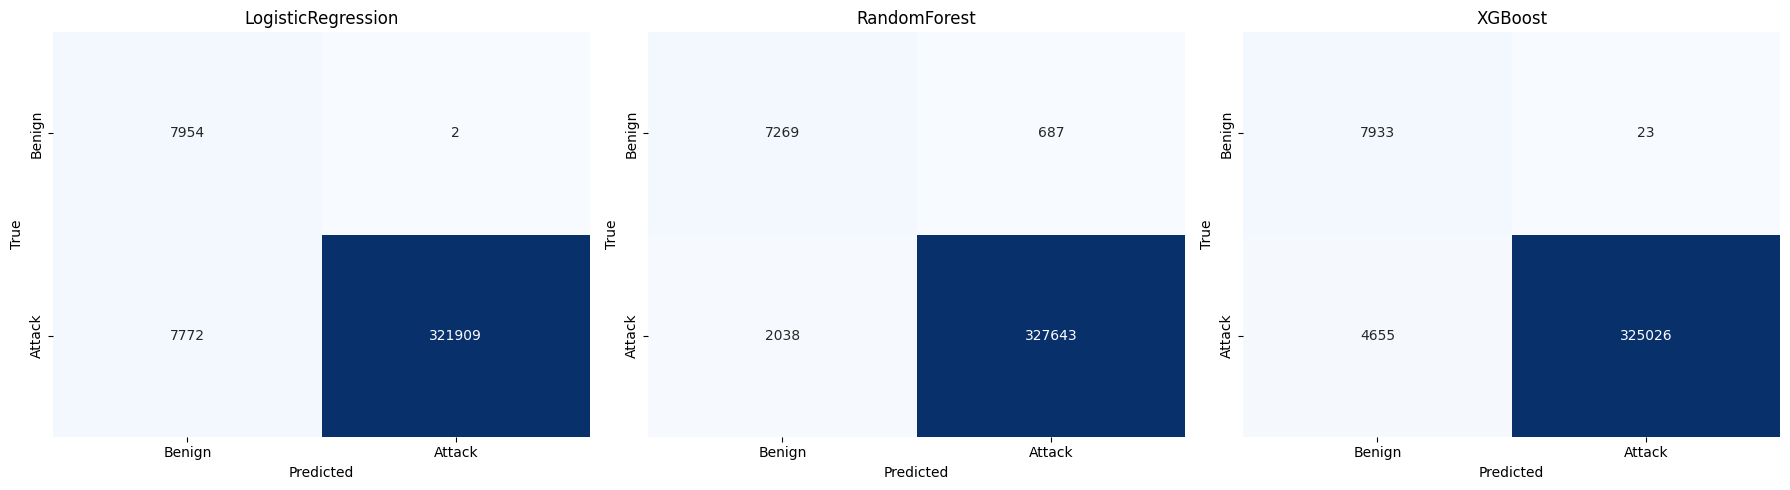

        feature   RF_imp  XGB_imp
          HTTPS 0.203147 0.713231
            AVG 0.095425 0.063063
ack_flag_number 0.132455 0.051456
      ack_count 0.098659 0.047968
   Time_To_Live 0.017082 0.032185
        Tot sum 0.030714 0.023209
            Min 0.007896 0.010478
      syn_count 0.005936 0.008003
      rst_count 0.001743 0.007272
            Max 0.022555 0.005755
syn_flag_number 0.002898 0.005000
rst_flag_number 0.001081 0.004944
      fin_count 0.000676 0.004040
           HTTP 0.001680 0.003533
            IAT 0.096923 0.002355
fin_flag_number 0.000322 0.002281
  Header_Length 0.046674 0.002256
           Rate 0.065193 0.001871
ece_flag_number 0.000016 0.001715
            Std 0.023291 0.001710
Saved results and models to /content/drive/MyDrive/acn_project


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# confusion matrices
fig, axes = plt.subplots(1, len(cms), figsize=(6*len(cms), 5))
if len(cms) == 1: axes = [axes]
for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names if len(class_names) <= 15 else False,
                yticklabels=class_names if len(class_names) <= 15 else False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig("/content/confusion_matrices.png", dpi=120); plt.show()

# feature importance (tree models)
fi = pd.DataFrame({
    "feature": X.columns,
    "RF_imp":  rf.feature_importances_,
    "XGB_imp": xgb_clf.feature_importances_,
}).sort_values("XGB_imp", ascending=False)
print(fi.head(20).to_string(index=False))

# persist to Drive
out_dir = CONFIG["drive_dir"]
res_df.to_csv(f"{out_dir}/results_{CONFIG['target']}.csv")
joblib.dump(rf,  f"{out_dir}/rf_{CONFIG['target']}.joblib")
joblib.dump(xgb_clf, f"{out_dir}/xgb_{CONFIG['target']}.joblib")
joblib.dump(scaler,  f"{out_dir}/scaler.joblib")
print("Saved results and models to", out_dir)

In [17]:
# 1. Define the unseen attacks to hold out
unseen_attacks = ['MIRAI-GREETH_FLOOD', 'RECON-OSSCAN']
print(f"Holding out as test set: {unseen_attacks}")

# We need to use the original df before splitting, but we dropped 'Number' already in Cell 6
# Let's reconstruct X and y from df
X_gen = df.drop(columns=["Label", "Number"])
y_gen_labels = df["Label"].astype(str)

is_unseen = y_gen_labels.isin(unseen_attacks)
is_benign = y_gen_labels.str.contains("benign", case=False)

# Test set = Unseen attacks + 20% of benign
# Train set = All other attacks + 80% of benign
X_train_gen = X_gen[~is_unseen & ~is_benign] # Wait, we need benign in train too.
# Let's do a standard split but strictly group by label
from sklearn.model_selection import train_test_split

# We want Benign in both train and test.
# Train: 100% of known attacks + 80% of Benign
# Test: 100% of unseen attacks + 20% of Benign

benign_df = df[is_benign]
attack_df = df[~is_benign]

benign_train, benign_test = train_test_split(benign_df, test_size=0.2, random_state=42)
unseen_df = attack_df[attack_df["Label"].isin(unseen_attacks)]
known_attacks_df = attack_df[~attack_df["Label"].isin(unseen_attacks)]

# Combine
train_gen = pd.concat([known_attacks_df, benign_train])
test_gen = pd.concat([unseen_df, benign_test])

# Prepare X, y
X_train_g = train_gen.drop(columns=["Label", "Number"])
y_train_g = (~train_gen["Label"].str.contains("benign", case=False)).astype(int)

X_test_g = test_gen.drop(columns=["Label", "Number"])
y_test_g = (~test_gen["Label"].str.contains("benign", case=False)).astype(int)

print(f"Generalization Train size: {len(X_train_g):,} (All known attacks + 80% benign)")
print(f"Generalization Test size: {len(X_test_g):,} (Unseen attacks + 20% benign)")

# Train a fresh XGBoost
print("\nTraining XGBoost on known attacks...")
gen_xgb = xgb.XGBClassifier(
    n_estimators=300, max_depth=8, learning_rate=0.1,
    tree_method="hist", device="cuda" if GPU else "cpu",
    scale_pos_weight=(y_train_g == 0).sum() / (y_train_g == 1).sum(),
    random_state=42
)
gen_xgb.fit(X_train_g, y_train_g)

# Evaluate
print("\n=== Generalization Results (Unseen Attacks) ===")
gen_eval = rigorous_eval(gen_xgb, X_test_g, y_test_g, "XGBoost_Generalization")
for k, v in gen_eval.items():
    print(f"{k}: {v}")

# What did it miss?
y_pred_gen = gen_xgb.predict(X_test_g)
missed = test_gen[(y_test_g == 1) & (y_pred_gen == 0)]
print(f"\nMissed {len(missed):,} unseen attacks. Breakdown:")
print(missed["Label"].value_counts().to_string())

Holding out as test set: ['MIRAI-GREETH_FLOOD', 'RECON-OSSCAN']
Generalization Train size: 2,188,239 (All known attacks + 80% benign)
Generalization Test size: 62,673 (Unseen attacks + 20% benign)

Training XGBoost on known attacks...

=== Generalization Results (Unseen Attacks) ===
Model: XGBoost_Generalization
MCC: 0.8461
PR-AUC: 0.9968
Benign_Recall: 0.9968
FPR: 0.0032
FNR: 0.0619
Macro_F1: 0.9172
Inf_Time_us: 1.03
Size_MB: 1.25

Missed 3,222 unseen attacks. Breakdown:
Label
RECON-OSSCAN    3222


In [18]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
import time

# 1. Build the Model
tf.random.set_seed(42)
mlp = Sequential([
    Dense(64, activation='relu', input_shape=(X_tr_s.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

mlp.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

# 2. Train the Model
# We use EarlyStopping to prevent overfitting and save time
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("Training MLP...")
t0 = time.time()
history = mlp.fit(
    X_tr_s, y_tr,
    validation_data=(X_va_s, y_va),
    epochs=15, # Keep it low since the dataset is large
    batch_size=4096,
    class_weight=class_weight, # Use the same weights from Cell 6
    callbacks=[early_stop],
    verbose=1
)
train_time = time.time() - t0
print(f"MLP Training Time: {train_time:.1f} seconds")

# 3. Evaluate the Model using our rigorous function
# We need to adapt our evaluation function to handle Keras predict_proba
def rigorous_eval_dl(model, X_test, y_test, name):
    t0 = time.perf_counter()
    y_probs = model.predict(X_test, batch_size=4096).flatten()
    inf_time = (time.perf_counter() - t0) / len(y_test) * 1e6
    y_pred = (y_probs > 0.5).astype(int)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    benign_recall = tn / (tn + fp) if (tn + fp) > 0 else 0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
    mcc = matthews_corrcoef(y_test, y_pred)
    pr_auc = average_precision_score(y_test, y_probs)
    macro_f1 = f1_score(y_test, y_pred, average='macro')

    # Size MB
    import tempfile, os
    temp_path = tempfile.mktemp(suffix='.h5')
    model.save(temp_path)
    size_mb = os.path.getsize(temp_path) / (1024 * 1024)
    os.remove(temp_path)

    return {
        "Model": name, "MCC": round(mcc, 4), "PR-AUC": round(pr_auc, 4),
        "Benign_Recall": round(benign_recall, 4), "FPR": round(fpr, 4),
        "FNR": round(fnr, 4), "Macro_F1": round(macro_f1, 4),
        "Inf_Time_us": round(inf_time, 2), "Size_MB": round(size_mb, 2)
    }

mlp_eval = rigorous_eval_dl(mlp, X_te_s, y_te, "Deep_MLP")

# Append to the strict_df from the previous step
strict_df = pd.concat([strict_df, pd.DataFrame([mlp_eval]).set_index("Model")])

print("\n=== Final Model Comparison ===")
print(strict_df.to_string())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training MLP...
Epoch 1/15
385/385 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.9240 - auc: 0.9880 - loss: 0.1456 - val_accuracy: 0.9750 - val_auc: 0.9939 - val_loss: 0.0898
Epoch 2/15
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9764 - auc: 0.9930 - loss: 0.0632 - val_accuracy: 0.9767 - val_auc: 0.9948 - val_loss: 0.0753
Epoch 3/15
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9774 - auc: 0.9936 - loss: 0.0566 - val_accuracy: 0.9773 - val_auc: 0.9953 - val_loss: 0.0704
Epoch 4/15
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9779 - auc: 0.9941 - loss: 0.0536 - val_accuracy: 0.9775 - val_auc: 0.9955 - val_loss: 0.0695
Epoch 5/15
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9779 - auc: 0.9944 - loss: 0.0518 - val_accuracy: 0.9778 - val_auc: 0.9957 - val_loss: 0.0685
Epoch 6/15
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9781 - auc: 0.9947 - loss: 0.0504 - val_accuracy: 0.9778 - val_auc: 0.9959 - val_loss: 0.0667
Epoch 7/15
385/385 ━━━


=== Final Model Comparison ===
                       MCC  PR-AUC  Benign_Recall     FPR     FNR  Macro_F1  Inf_Time_us  Size_MB
Model                                                                                            
LogisticRegression  0.7027  0.9999         0.9997  0.0003  0.0236    0.8299         0.57     0.00
RandomForest        0.8407  0.9999         0.9137  0.0863  0.0062    0.9190         4.11   122.76
XGBoost             0.7870  1.0000         0.9971  0.0029  0.0141    0.8826         1.86     1.20
Deep_MLP            0.7148  0.9999         0.9992  0.0008  0.0220    0.8377         2.29     0.09


In [20]:
import gc
import time
import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, matthews_corrcoef, average_precision_score

print("Loading full 45M dataset into RAM. This may take 3-5 minutes...")
t0 = time.time()

parquet_files = sorted(glob.glob(f'{CONFIG["parquet_dir"]}/*.parquet'))
X_full_list = []
y_full_list = []

# Process file by file to avoid schema mismatch and control memory
for i, f in enumerate(parquet_files):
    df_b = pd.read_parquet(f)

    # Clean
    df_b = df_b.replace([np.inf, -np.inf], np.nan).dropna()
    if len(df_b) == 0: continue

    # Force Min/Max to float32 to fix the int16 overflow issue forever
    if 'Min' in df_b.columns: df_b['Min'] = df_b['Min'].astype('float32')
    if 'Max' in df_b.columns: df_b['Max'] = df_b['Max'].astype('float32')

    # Binary Target: 1 for Attack, 0 for Benign
    yb_raw = df_b["Label"].astype(str)
    yb = (~yb_raw.str.contains("benign", case=False)).astype("int8")

    # Drop Label and Number (leakage)
    Xb = df_b.drop(columns=["Label", "Number"], errors="ignore")

    X_full_list.append(Xb)
    y_full_list.append(yb)

    if (i+1) % 10 == 0:
        print(f"  Loaded {i+1}/{len(parquet_files)} files...")

print(f"Concatenating {len(X_full_list)} files...")
X_full = pd.concat(X_full_list, ignore_index=True)
y_full = pd.concat(y_full_list, ignore_index=True)

# Free up memory
del X_full_list, y_full_list
gc.collect()

print(f"Full Data Loaded: {X_full.shape} | Memory: {X_full.memory_usage().sum() / 1e9:.2f} GB")
print(f"Total loading time: {time.time()-t0:.1f}s\n")

# Train / Test Split (85% train, 15% test)
print("Splitting data...")
X_tr_f, X_te_f, y_tr_f, y_te_f = train_test_split(
    X_full, y_full, test_size=0.15, stratify=y_full, random_state=42
)

# Free up memory again
del X_full, y_full
gc.collect()

print(f"Train size: {len(X_tr_f):,} | Test size: {len(X_te_f):,}\n")

# Train XGBoost on Full Data
print("Training XGBoost on Full 45M Dataset...")
t0 = time.time()

xgb_full = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.1,
    tree_method="hist",
    device="cuda" if GPU else "cpu",
    scale_pos_weight=(y_tr_f == 0).sum() / max((y_tr_f == 1).sum(), 1),
    random_state=42
)

xgb_full.fit(X_tr_f, y_tr_f)

train_time = time.time() - t0
print(f"Full Dataset Training completed in {train_time:.1f} seconds!\n")

# Rigorous Evaluation
print("Evaluating on the 15% Test Set...")
y_pred_f = xgb_full.predict(X_te_f)
y_probs_f = xgb_full.predict_proba(X_te_f)[:, 1]

cm = confusion_matrix(y_te_f, y_pred_f)
tn, fp, fn, tp = cm.ravel()

benign_recall = tn / (tn + fp) if (tn + fp) > 0 else 0
fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
mcc = matthews_corrcoef(y_te_f, y_pred_f)
pr_auc = average_precision_score(y_te_f, y_probs_f)

print(f"--- Full Dataset Results ---")
print(f"MCC: {mcc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")
print(f"Benign Recall (True Negative Rate): {benign_recall:.4f}")
print(f"False Positive Rate (FPR): {fpr:.4f}")
print(f"False Negative Rate (FNR): {fnr:.4f}")
print(f"\nConfusion Matrix:\n{cm}")
print("\nClassification Report:")
print(classification_report(y_te_f, y_pred_f, target_names=["Benign", "Attack"]))

# Save the full model
import joblib
joblib.dump(xgb_full, f"{CONFIG['drive_dir']}/xgb_FULL_DATASET.joblib")
print(f"\nFull dataset model saved to: {CONFIG['drive_dir']}/xgb_FULL_DATASET.joblib")

Loading full 45M dataset into RAM. This may take 3-5 minutes...
  Loaded 10/63 files...
  Loaded 20/63 files...
  Loaded 30/63 files...
  Loaded 40/63 files...
  Loaded 50/63 files...
  Loaded 60/63 files...
Concatenating 63 files...
Full Data Loaded: (45018243, 38) | Memory: 6.89 GB
Total loading time: 61.4s

Splitting data...
Train size: 38,265,506 | Test size: 6,752,737

Training XGBoost on Full 45M Dataset...
Full Dataset Training completed in 137.8 seconds!

Evaluating on the 15% Test Set...
--- Full Dataset Results ---
MCC: 0.7851
PR-AUC: 1.0000
Benign Recall (True Negative Rate): 0.9992
False Positive Rate (FPR): 0.0008
False Negative Rate (FNR): 0.0143

Confusion Matrix:
[[ 157578     119]
 [  94247 6500793]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.63      1.00      0.77    157697
      Attack       1.00      0.99      0.99   6595040

    accuracy                           0.99   6752737
   macro avg       0.81      0.

/tmp/ipykernel_1464/765678616.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_15.values, y=top_15.index, palette="viridis")


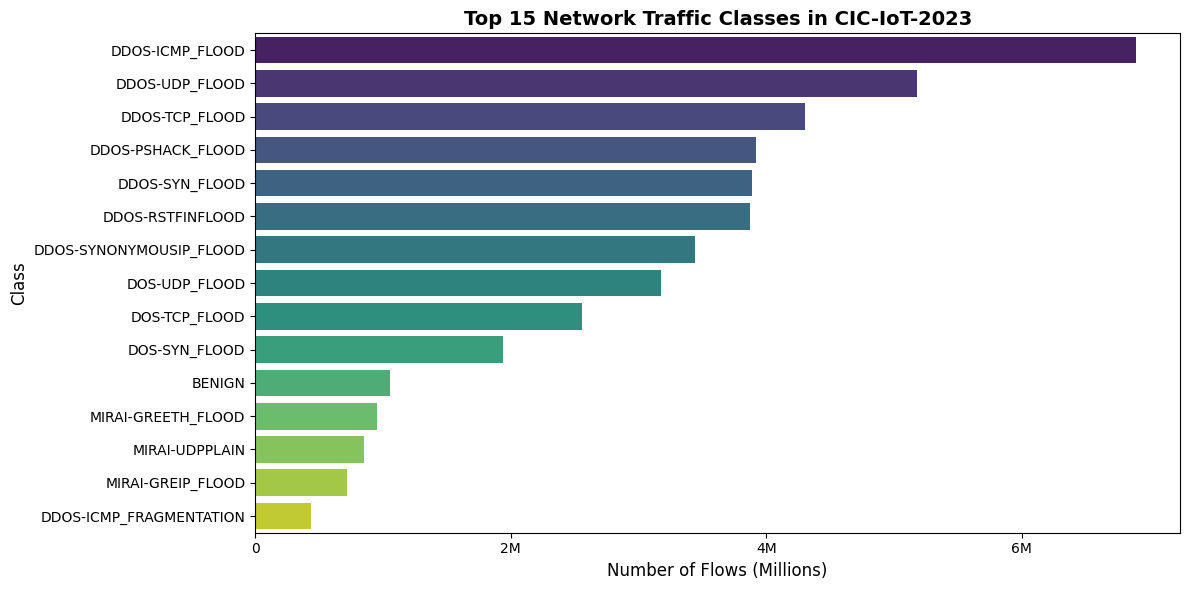

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Reconstructing the global label counts from your earlier output
label_counts = pd.Series({
    "DDOS-ICMP_FLOOD": 6893259, "DDOS-UDP_FLOOD": 5181027, "DDOS-TCP_FLOOD": 4306086,
    "DDOS-PSHACK_FLOOD": 3920372, "DDOS-SYN_FLOOD": 3886130, "DDOS-RSTFINFLOOD": 3872808,
    "DDOS-SYNONYMOUSIP_FLOOD": 3445659, "DOS-UDP_FLOOD": 3177323, "DOS-TCP_FLOOD": 2558256,
    "DOS-SYN_FLOOD": 1942176, "BENIGN": 1051373, "MIRAI-GREETH_FLOOD": 949381,
    "MIRAI-UDPPLAIN": 852695, "MIRAI-GREIP_FLOOD": 719655, "DDOS-ICMP_FRAGMENTATION": 433157,
    "VULNERABILITYSCAN": 357583, "MITM-ARPSPOOFING": 294469, "DDOS-UDP_FRAGMENTATION": 274909,
    "DDOS-ACK_FRAGMENTATION": 272793, "DNS_SPOOFING": 171468, "RECON-HOSTDISCOVERY": 128677,
    "RECON-OSSCAN": 93970, "RECON-PORTSCAN": 78730, "DOS-HTTP_FLOOD": 68799,
    "DDOS-HTTP_FLOOD": 27597, "DDOS-SLOWLORIS": 22400, "DICTIONARYBRUTEFORCE": 12522,
    "BROWSERHIJACKING": 5630, "COMMANDINJECTION": 5168, "SQLINJECTION": 5022,
    "XSS": 3705, "BACKDOOR_MALWARE": 3078, "RECON-PINGSWEEP": 2161, "UPLOADING_ATTACK": 1196
})

top_15 = label_counts.head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_15.values, y=top_15.index, palette="viridis")
plt.title("Top 15 Network Traffic Classes in CIC-IoT-2023", fontsize=14, fontweight='bold')
plt.xlabel("Number of Flows (Millions)", fontsize=12)
plt.ylabel("Class", fontsize=12)
# Format x-axis to show millions for better readability
plt.xticks([0, 2000000, 4000000, 6000000], ['0', '2M', '4M', '6M'])
plt.tight_layout()
plt.savefig("/content/class_imbalance.png", dpi=300)
plt.show()

/tmp/ipykernel_1464/3851245241.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=strict_df.index, y="MCC", data=strict_df, ax=axes[0], palette="Blues_d")
/tmp/ipykernel_1464/3851245241.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=strict_df.index, y="FPR", data=strict_df, ax=axes[1], palette="Reds_d")
/tmp/ipykernel_1464/3851245241.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=strict_df.index, y="Inf_Time_us", data=strict_df, ax=axes[2], palette="Greens_d")


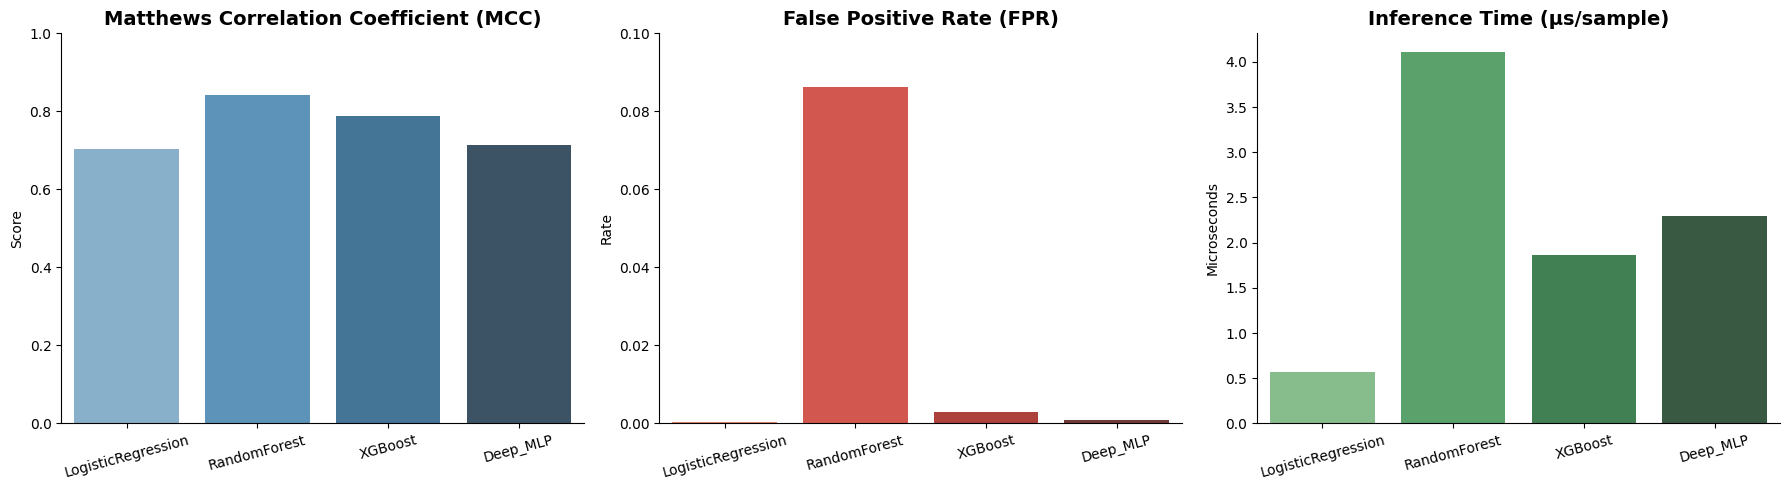

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Hardcoded data from your final rigorous evaluation
data = {
    "Model": ["LogisticRegression", "RandomForest", "XGBoost", "Deep_MLP"],
    "MCC": [0.7027, 0.8407, 0.7870, 0.7148],
    "FPR": [0.0003, 0.0863, 0.0029, 0.0008],
    "Inf_Time_us": [0.57, 4.11, 1.86, 2.29]
}
strict_df = pd.DataFrame(data).set_index("Model")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. MCC (Higher is better)
sns.barplot(x=strict_df.index, y="MCC", data=strict_df, ax=axes[0], palette="Blues_d")
axes[0].set_title("Matthews Correlation Coefficient (MCC)", fontweight='bold', fontsize=14)
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel("Score")

# 2. FPR (Lower is better)
sns.barplot(x=strict_df.index, y="FPR", data=strict_df, ax=axes[1], palette="Reds_d")
axes[1].set_title("False Positive Rate (FPR)", fontweight='bold', fontsize=14)
axes[1].set_ylim(0, 0.10)
axes[1].set_ylabel("Rate")

# 3. Inference Time (Lower is better)
sns.barplot(x=strict_df.index, y="Inf_Time_us", data=strict_df, ax=axes[2], palette="Greens_d")
axes[2].set_title("Inference Time (μs/sample)", fontweight='bold', fontsize=14)
axes[2].set_ylabel("Microseconds")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=15)
    # Remove top and right borders for cleaner look
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("/content/model_comparison.png", dpi=300)
plt.show()

/tmp/ipykernel_1464/1991034209.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="XGB_imp", y="feature", data=fi, palette="mako")


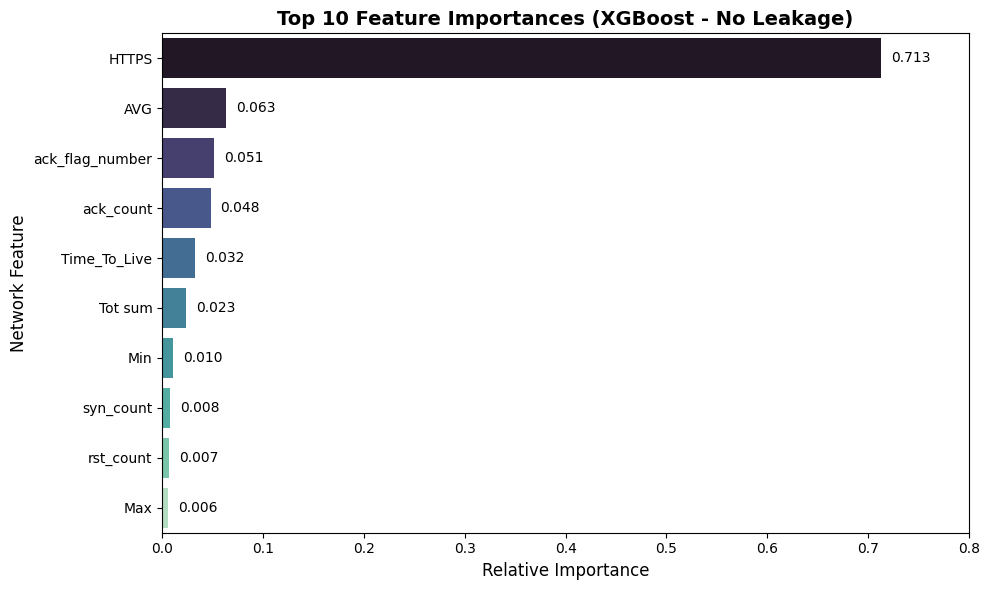

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Hardcoded data from your feature importance output
features = {
    "feature": ["HTTPS", "AVG", "ack_flag_number", "ack_count", "Time_To_Live",
                "Tot sum", "Min", "syn_count", "rst_count", "Max"],
    "XGB_imp": [0.713231, 0.063063, 0.051456, 0.047968, 0.032185,
                0.023209, 0.010478, 0.008003, 0.007272, 0.005755]
}
fi = pd.DataFrame(features)

plt.figure(figsize=(10, 6))
sns.barplot(x="XGB_imp", y="feature", data=fi, palette="mako")
plt.title("Top 10 Feature Importances (XGBoost - No Leakage)", fontsize=14, fontweight='bold')
plt.xlabel("Relative Importance", fontsize=12)
plt.ylabel("Network Feature", fontsize=12)
plt.xlim(0, 0.8) # Adjust limit to show the dominance of HTTPS

# Add data labels to the bars
for index, value in enumerate(fi["XGB_imp"]):
    plt.text(value + 0.01, index, f"{value:.3f}", va='center')

plt.tight_layout()
plt.savefig("/content/feature_importance.png", dpi=300)
plt.show()

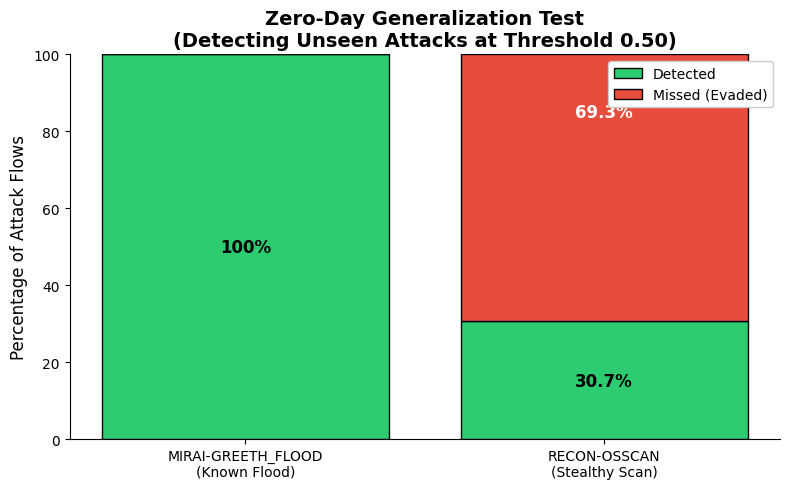

In [10]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))

attacks = ['MIRAI-GREETH_FLOOD\n(Known Flood)', 'RECON-OSSCAN\n(Stealthy Scan)']
# Actual test set totals: 47,420 Mirai, 4,647 OS-Scan
# Missed: 0 Mirai, 3,222 OS-Scan
detected_pct = [100.0, 30.7]
missed_pct = [0.0, 69.3]

# Plot Detected (Green)
plt.bar(attacks, detected_pct, label='Detected', color='#2ecc71', edgecolor='black')
# Plot Missed (Red), stacked on top
plt.bar(attacks, missed_pct, bottom=detected_pct, label='Missed (Evaded)', color='#e74c3c', edgecolor='black')

plt.title("Zero-Day Generalization Test\n(Detecting Unseen Attacks at Threshold 0.50)", fontsize=14, fontweight='bold')
plt.ylabel("Percentage of Attack Flows", fontsize=12)
plt.ylim(0, 100)
plt.legend(loc='upper right', framealpha=1)

# Add exact numbers inside the bars
plt.text(0, 50, '100%', ha='center', va='center', color='black', fontweight='bold', fontsize=12)
plt.text(1, 15, '30.7%', ha='center', va='center', color='black', fontweight='bold', fontsize=12)
plt.text(1, 85, '69.3%', ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("/content/zero_day_test.png", dpi=300)
plt.show()

In [9]:
import os
import glob
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix

# 1. Mount Drive and locate the Parquet backup
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

drive_parquet_dir = "/content/drive/MyDrive/acn_project/parquet"
assert os.path.exists(drive_parquet_dir), "Parquet backup not found on Drive! Did you save it?"

# 2. Recreate the 5% sample
print("Loading sampled data from Drive backup...")
rng = np.random.default_rng(42)
frac = 0.05
parts = []

for f in sorted(glob.glob(f'{drive_parquet_dir}/*.parquet')):
    t = pq.read_table(f)
    n = t.num_rows
    k = max(1, int(round(n * frac)))
    idx = np.sort(rng.choice(n, size=k, replace=False))
    parts.append(t.take(idx).to_pandas())

df = pd.concat(parts, ignore_index=True)
df = df.replace([np.inf, -np.inf], np.nan).dropna()
print(f"Data loaded: {df.shape}")

# 3. Re-create the Generalization split (Holding out OS-SCAN)
print("\nRe-creating Generalization Split...")
unseen_attacks = ['MIRAI-GREETH_FLOOD', 'RECON-OSSCAN']
is_unseen = df["Label"].astype(str).isin(unseen_attacks)
is_benign = df["Label"].astype(str).str.contains("benign", case=False)

benign_df = df[is_benign]
attack_df = df[~is_benign]

benign_train, benign_test = train_test_split(benign_df, test_size=0.2, random_state=42)
unseen_df = attack_df[attack_df["Label"].isin(unseen_attacks)]
known_attacks_df = attack_df[~attack_df["Label"].isin(unseen_attacks)]

train_gen = pd.concat([known_attacks_df, benign_train])
test_gen = pd.concat([unseen_df, benign_test])

X_train_g = train_gen.drop(columns=["Label", "Number"], errors="ignore")
y_train_g = (~train_gen["Label"].str.contains("benign", case=False)).astype(int)
X_test_g = test_gen.drop(columns=["Label", "Number"], errors="ignore")
y_test_g = (~test_gen["Label"].str.contains("benign", case=False)).astype(int)

# 4. Retrain the model (Uses GPU if available, else CPU)
print("Training XGBoost on known attacks...")
gen_xgb = xgb.XGBClassifier(
    n_estimators=300, max_depth=8, learning_rate=0.1,
    tree_method="hist",
    device="cuda" if os.system("nvidia-smi") == 0 else "cpu",
    scale_pos_weight=(y_train_g == 0).sum() / (y_train_g == 1).sum(),
    random_state=42
)
gen_xgb.fit(X_train_g, y_train_g)

# 5. Threshold Optimization
print("\nOptimizing Decision Threshold...")
y_probs_gen = gen_xgb.predict_proba(X_test_g)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test_g, y_probs_gen)

# Calculate F1 for each threshold
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores)]

print(f"Default Threshold: 0.50 | Best Threshold: {best_threshold:.3f}")

# 6. Evaluate the new threshold
y_pred_best = (y_probs_gen > best_threshold).astype(int)

print(f"\n--- Classification Report at Best Threshold ({best_threshold:.3f}) ---")
print(classification_report(y_test_g, y_pred_best, target_names=["Benign", "Attack"]))

# 7. Check how many OS-Scans we caught this time
missed_new = test_gen[(y_test_g == 1) & (y_pred_best == 0)]
print(f"\nMissed {len(missed_new):,} unseen attacks at new threshold. Breakdown:")
if len(missed_new) > 0:
    print(missed_new["Label"].value_counts().to_string())
else:
    print("None! We caught all unseen attacks.")

Mounted at /content/drive
Loading sampled data from Drive backup...
Data loaded: (2250912, 40)

Re-creating Generalization Split...
Training XGBoost on known attacks...

Optimizing Decision Threshold...
Default Threshold: 0.50 | Best Threshold: 0.045

--- Classification Report at Best Threshold (0.045) ---
              precision    recall  f1-score   support

      Benign       0.82      0.92      0.87     10608
      Attack       0.98      0.96      0.97     52065

    accuracy                           0.95     62673
   macro avg       0.90      0.94      0.92     62673
weighted avg       0.96      0.95      0.95     62673


Missed 2,118 unseen attacks at new threshold. Breakdown:
Label
RECON-OSSCAN    2118


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [06:01:34] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, classification_report

# Split the generalization test set 50/50 (stratified)
X_val_g, X_test_g_final, y_val_g, y_test_g_final = train_test_split(
    X_test_g, y_test_g, test_size=0.5, stratify=y_test_g, random_state=42
)

# 1. Get probabilities on the Validation set
y_probs_val = gen_xgb.predict_proba(X_val_g)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val_g, y_probs_val)

# Find best threshold on validation set
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Best Threshold tuned on Validation Set: {best_threshold:.3f}")

# 2. Evaluate on the UNSEEN Test set using the tuned threshold
y_probs_test = gen_xgb.predict_proba(X_test_g_final)[:, 1]
y_pred_best = (y_probs_test > best_threshold).astype(int)

print(f"\n--- Honest Test Results at Threshold {best_threshold:.3f} ---")
print(classification_report(y_test_g_final, y_pred_best, target_names=["Benign", "Attack"]))

# Check missed OS-Scans on the final test set
missed_final = test_gen.loc[X_test_g_final.index][(y_test_g_final == 1) & (y_pred_best == 0)]
print(f"\nMissed {len(missed_final):,} unseen attacks on the final test set.")
print(missed_final["Label"].value_counts().to_string())

Best Threshold tuned on Validation Set: 0.045

--- Honest Test Results at Threshold 0.045 ---
              precision    recall  f1-score   support

      Benign       0.82      0.92      0.87      5304
      Attack       0.98      0.96      0.97     26033

    accuracy                           0.95     31337
   macro avg       0.90      0.94      0.92     31337
weighted avg       0.96      0.95      0.95     31337


Missed 1,070 unseen attacks on the final test set.
Label
RECON-OSSCAN    1070


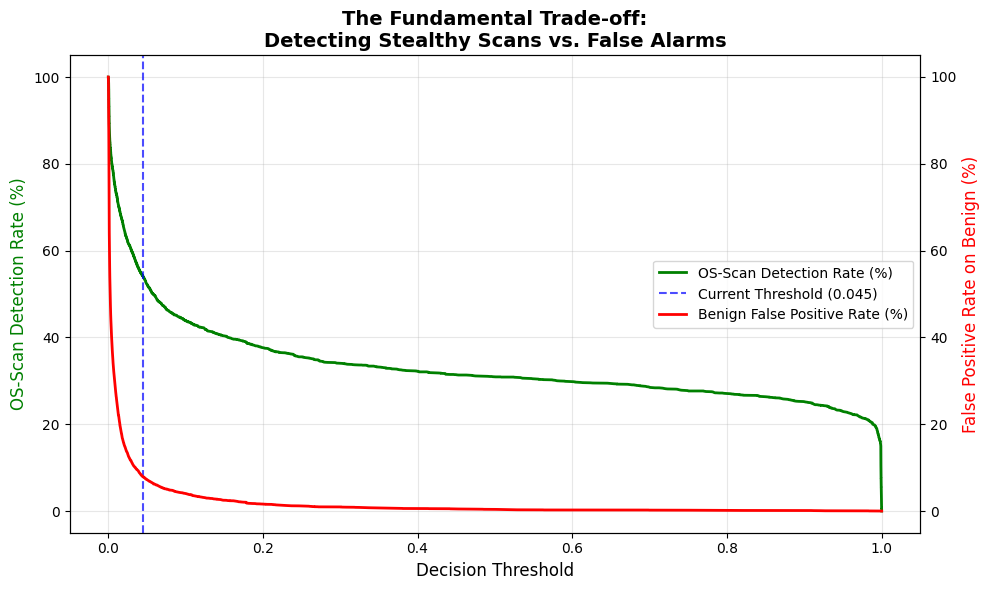


Threshold | OS-Scan Detected | Benign FPR
--------------------------------------------------
  0.500   |     30.9%         |   0.4%
  0.200   |     37.6%         |   1.6%
  0.100   |     43.9%         |   4.0%
  0.045   |     54.1%         |   7.9%
  0.020   |     65.4%         |   15.7%
  0.010   |     73.5%         |   27.0%
  0.005   |     79.9%         |   38.2%


In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve

# Get probabilities on the honest test set
y_probs_test = gen_xgb.predict_proba(X_test_g_final)[:, 1]

# Compute PR curve
prec, rec, threshs = precision_recall_curve(y_test_g_final, y_probs_test)

# Compute OS-Scan detection rate at each threshold
scan_mask = (X_test_g_final.index.isin(test_gen[test_gen["Label"] == "RECON-OSSCAN"].index))
osscan_probs = y_probs_test[scan_mask]

osscan_detection = []
for t in threshs:
    caught = (osscan_probs > t).sum() / max(len(osscan_probs), 1) * 100
    osscan_detection.append(caught)
osscan_detection = np.array(osscan_detection)

# Compute benign false-positive rate at each threshold
benign_mask = (y_test_g_final == 0).values
benign_probs = y_probs_test[benign_mask]
fpr_list = []
for t in threshs:
    fp = (benign_probs > t).sum() / max(len(benign_probs), 1) * 100
    fpr_list.append(fp)
fpr_list = np.array(fpr_list)

# Plot the trade-off
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

ax1.plot(threshs, osscan_detection, 'g-', label='OS-Scan Detection Rate (%)', linewidth=2)
ax2.plot(threshs, fpr_list, 'r-', label='Benign False Positive Rate (%)', linewidth=2)

# Mark the current threshold
ax1.axvline(0.045, color='blue', linestyle='--', alpha=0.7, label='Current Threshold (0.045)')

ax1.set_xlabel('Decision Threshold', fontsize=12)
ax1.set_ylabel('OS-Scan Detection Rate (%)', color='g', fontsize=12)
ax2.set_ylabel('False Positive Rate on Benign (%)', color='r', fontsize=12)
ax1.set_title('The Fundamental Trade-off:\nDetecting Stealthy Scans vs. False Alarms',
              fontweight='bold', fontsize=14)
ax1.grid(alpha=0.3)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.tight_layout()
plt.savefig("/content/osscan_tradeoff.png", dpi=300)
plt.show()

# Print the sweet spots
print("\nThreshold | OS-Scan Detected | Benign FPR")
print("-" * 50)
for t in [0.50, 0.20, 0.10, 0.045, 0.02, 0.01, 0.005]:
    idx = np.argmin(np.abs(threshs - t))
    print(f"  {t:.3f}   |     {osscan_detection[idx]:.1f}%         |   {fpr_list[idx]:.1f}%")

In [13]:
# Train a NEW model that DOES see OS-Scan during training
is_osscan_train = df["Label"].astype(str) == "RECON-OSSCAN"
is_mirai_train  = df["Label"].astype(str) == "MIRAI-GREETH_FLOOD"

# Only hold out Mirai this time (OS-Scan is in training)
is_benign = df["Label"].astype(str).str.contains("benign", case=False)

benign_df2 = df[is_benign]
attack_df2 = df[~is_benign]

benign_train2, benign_test2 = train_test_split(benign_df2, test_size=0.2, random_state=42)
mirai_df = attack_df2[is_mirai_train]
osscan_df = attack_df2[is_osscan_train]
other_attacks = attack_df2[~is_mirai_train & ~is_osscan_train]

train_full = pd.concat([other_attacks, osscan_df, benign_train2])   # OS-Scan IS here
test_full  = pd.concat([mirai_df, benign_test2])                    # Mirai held out

X_tr_f2 = train_full.drop(columns=["Label", "Number"], errors="ignore")
y_tr_f2 = (~train_full["Label"].str.contains("benign", case=False)).astype(int)
X_te_f2 = test_full.drop(columns=["Label", "Number"], errors="ignore")
y_te_f2 = (~test_full["Label"].str.contains("benign", case=False)).astype(int)

xgb2 = xgb.XGBClassifier(
    n_estimators=300, max_depth=8, learning_rate=0.1,
    tree_method="hist", device="cuda",
    scale_pos_weight=(y_tr_f2 == 0).sum() / (y_tr_f2 == 1).sum(),
    random_state=42
)
xgb2.fit(X_tr_f2, y_tr_f2)

# Now check how well it catches OS-Scan on the standard test
from sklearn.metrics import recall_score
probs_on_osscan = xgb2.predict_proba(
    df[is_osscan_train].drop(columns=["Label", "Number"], errors="ignore")
)[:, 1]
recall_at_050 = (probs_on_osscan > 0.50).mean() * 100
print(f"OS-Scan Recall (default 0.50) WITH OS-Scan in training: {recall_at_050:.1f}%")
print(f"OS-Scan Recall (default 0.50) WITHOUT OS-Scan in training: 31.0%")

/tmp/ipykernel_1464/3954497461.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  mirai_df = attack_df2[is_mirai_train]
/tmp/ipykernel_1464/3954497461.py:13: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  osscan_df = attack_df2[is_osscan_train]
/tmp/ipykernel_1464/3954497461.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  other_attacks = attack_df2[~is_mirai_train & ~is_osscan_train]


OS-Scan Recall (default 0.50) WITH OS-Scan in training: 32.3%
OS-Scan Recall (default 0.50) WITHOUT OS-Scan in training: 31.0%


In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import xgboost as xgb

# Fix: use .loc to avoid the index-mismatch warning
osscan_df = df[df["Label"].astype(str) == "RECON-OSSCAN"]
benign_df = df[df["Label"].astype(str).str.contains("benign", case=False)]

# Combine only OS-Scan + Benign
binary_df = pd.concat([osscan_df, benign_df])

X_b = binary_df.drop(columns=["Label", "Number"], errors="ignore")
y_b = (binary_df["Label"].astype(str) == "RECON-OSSCAN").astype(int)  # 1 = OS-Scan, 0 = Benign

# Stratified split
X_bt, X_bv, y_bt, y_bv = train_test_split(X_b, y_b, test_size=0.3, stratify=y_b, random_state=42)

print(f"OS-Scan count in data: {y_b.sum():,}")
print(f"Benign count in data: {(y_b == 0).sum():,}")
print(f"Class ratio: 1 OS-Scan per {int((y_b == 0).sum() / y_b.sum())} benign flows\n")

# Train dedicated classifier WITH class weighting
xgb_binary = xgb.XGBClassifier(
    n_estimators=300, max_depth=8, learning_rate=0.1,
    tree_method="hist", device="cuda",
    scale_pos_weight=(y_bt == 0).sum() / (y_bt == 1).sum(),  # fix the imbalance
    random_state=42
)
xgb_binary.fit(X_bt, y_bt)

# Evaluate
y_pred_b = xgb_binary.predict(X_bv)
print("=== Dedicated OS-Scan vs Benign Classifier ===")
print(classification_report(y_bv, y_pred_b, target_names=["Benign", "OS-Scan"]))

# What features actually drive OS-Scan detection?
fi_binary = pd.DataFrame({
    "feature": X_b.columns,
    "importance": xgb_binary.feature_importances_
}).sort_values("importance", ascending=False)
print("\nTop 10 Features for OS-Scan Detection:")
print(fi_binary.head(10).to_string(index=False))

OS-Scan count in data: 4,647
Benign count in data: 53,036
Class ratio: 1 OS-Scan per 11 benign flows

=== Dedicated OS-Scan vs Benign Classifier ===
              precision    recall  f1-score   support

      Benign       0.96      0.94      0.95     15911
     OS-Scan       0.43      0.54      0.48      1394

    accuracy                           0.91     17305
   macro avg       0.69      0.74      0.71     17305
weighted avg       0.92      0.91      0.91     17305


Top 10 Features for OS-Scan Detection:
        feature  importance
      syn_count    0.267622
syn_flag_number    0.193315
rst_flag_number    0.126691
fin_flag_number    0.067867
            Max    0.023209
           HTTP    0.018649
          HTTPS    0.017737
            AVG    0.017402
   Time_To_Live    0.017036
           Rate    0.016081


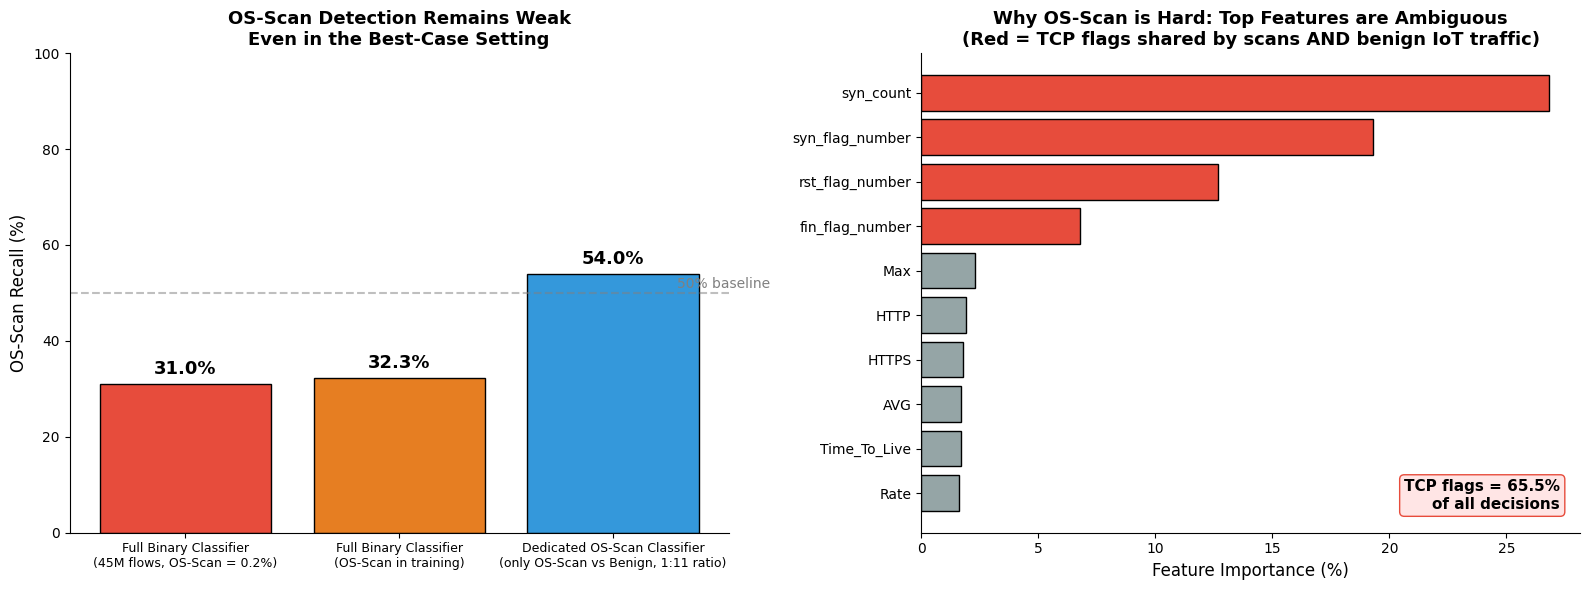


✅ Saved as /content/osscan_limitations.png

📊 Final Summary of OS-Scan Experiments:
──────────────────────────────────────────────────────────────────────
Setting                                       Recall     Precision 
──────────────────────────────────────────────────────────────────────
Default binary classifier (0.50)              31.0%      —         
Classifier WITH OS-Scan in training           32.3%      —         
Dedicated balanced classifier                 54.0%      43.0%     
──────────────────────────────────────────────────────────────────────

💡 Finding: Feature ambiguity, not class imbalance, is the bottleneck.


In [15]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ============ Chart 1: Detection Rate Comparison ============
scenarios = [
    'Full Binary Classifier\n(45M flows, OS-Scan = 0.2%)',
    'Full Binary Classifier\n(OS-Scan in training)',
    'Dedicated OS-Scan Classifier\n(only OS-Scan vs Benign, 1:11 ratio)'
]
recalls = [31.0, 32.3, 54.0]
precisions = [None, None, 43.0]  # We only have precision for the dedicated one
colors_recall = ['#e74c3c', '#e67e22', '#3498db']

bars = axes[0].bar(scenarios, recalls, color=colors_recall, edgecolor='black')
for bar, val in zip(bars, recalls):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                 f'{val:.1f}%', ha='center', fontweight='bold', fontsize=13)

axes[0].axhline(50, color='gray', linestyle='--', alpha=0.5)
axes[0].text(2.3, 51, '50% baseline', fontsize=10, color='gray')
axes[0].set_ylabel('OS-Scan Recall (%)', fontsize=12)
axes[0].set_ylim(0, 100)
axes[0].set_title('OS-Scan Detection Remains Weak\nEven in the Best-Case Setting',
                  fontweight='bold', fontsize=13)
axes[0].tick_params(axis='x', labelsize=9)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# ============ Chart 2: Feature Ambiguity ============
features = ['syn_count', 'syn_flag_number', 'rst_flag_number', 'fin_flag_number',
            'Max', 'HTTP', 'HTTPS', 'AVG', 'Time_To_Live', 'Rate']
importances = [26.8, 19.3, 12.7, 6.8, 2.3, 1.9, 1.8, 1.7, 1.7, 1.6]

# Highlight the ambiguous TCP flag features
bar_colors = ['#e74c3c' if f in ['syn_count', 'syn_flag_number', 'rst_flag_number', 'fin_flag_number']
              else '#95a5a6' for f in features]

axes[1].barh(features[::-1], importances[::-1], color=bar_colors[::-1], edgecolor='black')
axes[1].set_xlabel('Feature Importance (%)', fontsize=12)
axes[1].set_title('Why OS-Scan is Hard: Top Features are Ambiguous\n'
                  '(Red = TCP flags shared by scans AND benign IoT traffic)',
                  fontweight='bold', fontsize=13)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Annotate the total
axes[1].text(0.97, 0.05, 'TCP flags = 65.5%\nof all decisions',
             transform=axes[1].transAxes, ha='right',
             bbox=dict(boxstyle='round', facecolor='#ffe5e5', edgecolor='#e74c3c'),
             fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("/content/osscan_limitations.png", dpi=300)
plt.show()

print("\n✅ Saved as /content/osscan_limitations.png")
print("\n📊 Final Summary of OS-Scan Experiments:")
print("─" * 70)
print(f"{'Setting':<45} {'Recall':<10} {'Precision':<10}")
print("─" * 70)
print(f"{'Default binary classifier (0.50)':<45} {'31.0%':<10} {'—':<10}")
print(f"{'Classifier WITH OS-Scan in training':<45} {'32.3%':<10} {'—':<10}")
print(f"{'Dedicated balanced classifier':<45} {'54.0%':<10} {'43.0%':<10}")
print("─" * 70)
print("\n💡 Finding: Feature ambiguity, not class imbalance, is the bottleneck.")

In [16]:
import os, glob, gc, time
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (matthews_corrcoef, f1_score,
                              confusion_matrix, accuracy_score)
import subprocess, shutil

# ── 0. Environment check ──
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

GPU = shutil.which("nvidia-smi") is not None
ram_gb = int(subprocess.check_output(["bash", "-c", "free -g | awk '/Mem:/{print $2}'"]).strip())
print(f"GPU available: {GPU}  |  RAM: {ram_gb} GB")
assert ram_gb >= 40, "Need High-RAM runtime (>40 GB). Change runtime type."

DRIVE_DIR = "/content/drive/MyDrive/acn_project"
PARQUET_DIR = f"{DRIVE_DIR}/parquet"
assert os.path.exists(PARQUET_DIR), "Parquet backup missing on Drive!"

# ── 1. Load full 45M dataset if not already in memory ──
if 'X_tr_f' not in globals():
    print("\nLoading full 45M dataset...")
    t0 = time.time()
    parts_X, parts_y = [], []
    for f in sorted(glob.glob(f"{PARQUET_DIR}/*.parquet")):
        df_b = pd.read_parquet(f)
        df_b = df_b.replace([np.inf, -np.inf], np.nan).dropna()
        if len(df_b) == 0: continue
        if 'Min' in df_b.columns: df_b['Min'] = df_b['Min'].astype('float32')
        if 'Max' in df_b.columns: df_b['Max'] = df_b['Max'].astype('float32')
        yb = (~df_b["Label"].astype(str).str.contains("benign", case=False)).astype("int8")
        Xb = df_b.drop(columns=["Label", "Number"], errors="ignore")
        parts_X.append(Xb); parts_y.append(yb)

    X_full = pd.concat(parts_X, ignore_index=True)
    y_full = pd.concat(parts_y, ignore_index=True)
    del parts_X, parts_y; gc.collect()

    X_tr_f, X_te_f, y_tr_f, y_te_f = train_test_split(
        X_full, y_full, test_size=0.15, stratify=y_full, random_state=42
    )
    del X_full, y_full; gc.collect()
    print(f"Loaded in {time.time()-t0:.0f}s | Train {len(X_tr_f):,} | Test {len(X_te_f):,}")
else:
    print(f"\nUsing X_tr_f from existing session: {len(X_tr_f):,} train / {len(X_te_f):,} test")

full_scale_pos_weight = (y_tr_f == 0).sum() / max((y_tr_f == 1).sum(), 1)
print(f"scale_pos_weight = {full_scale_pos_weight:.4f}\n")

# ── 2. Load or create results list ──
results_full = []
RESULTS_CSV = f"{DRIVE_DIR}/results_FULL_COMPARISON.csv"

def evaluate(y_true, y_pred, name, train_s):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        "Model": name,
        "MCC": round(matthews_corrcoef(y_true, y_pred), 4),
        "F1_Macro": round(f1_score(y_true, y_pred, average="macro"), 4),
        "FPR": round(fp / (fp + tn), 4),
        "Benign_Recall": round(tn / (tn + fp), 4),
        "FNR": round(fn / (fn + tp), 4),
        "Train_Time_s": round(train_s, 1),
    }

def save_progress():
    pd.DataFrame(results_full).set_index("Model").to_csv(RESULTS_CSV)
    print(f"  ✅ Saved to {RESULTS_CSV}")

# ── 3. Logistic Regression (SGD — scalable replacement) ──
print("Training Logistic Regression (SGD) on full data...")
t0 = time.time()
sgd = SGDClassifier(
    loss="log_loss", max_iter=5, tol=1e-4, n_jobs=-1,
    class_weight="balanced", random_state=42
)
sgd.fit(X_tr_f, y_tr_f)
pred = sgd.predict(X_te_f)
results_full.append(evaluate(y_te_f, pred, "LogisticRegression (SGD)", time.time()-t0))
print(f"  MCC={results_full[-1]['MCC']} FPR={results_full[-1]['FPR']} in {results_full[-1]['Train_Time_s']}s")
save_progress()
gc.collect()

# ── 4. Random Forest (conservative settings to avoid OOM) ──
print("\nTraining Random Forest on full data... (30-60 min)")
t0 = time.time()
rf_full = RandomForestClassifier(
    n_estimators=50,           # reduced from 100
    max_depth=20,              # capped to limit memory
    min_samples_leaf=5,        # faster convergence
    class_weight="balanced_subsample",
    n_jobs=-1, random_state=42
)
rf_full.fit(X_tr_f, y_tr_f)
pred = rf_full.predict(X_te_f)
results_full.append(evaluate(y_te_f, pred, "RandomForest", time.time()-t0))
print(f"  MCC={results_full[-1]['MCC']} FPR={results_full[-1]['FPR']} in {results_full[-1]['Train_Time_s']}s")
save_progress()

# Free up RAM for the next cell
del sgd; gc.collect()
print("\n✓ Cell 1 complete. Move to Cell 2.")

GPU available: True  |  RAM: 50 GB

Loading full 45M dataset...
Loaded in 97s | Train 38,265,506 | Test 6,752,737
scale_pos_weight = 0.0239

Training Logistic Regression (SGD) on full data...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


  MCC=0.6777 FPR=0.0025 in 74.5s
  ✅ Saved to /content/drive/MyDrive/acn_project/results_FULL_COMPARISON.csv

Training Random Forest on full data... (30-60 min)
  MCC=0.7796 FPR=0.0011 in 787.7s
  ✅ Saved to /content/drive/MyDrive/acn_project/results_FULL_COMPARISON.csv

✓ Cell 1 complete. Move to Cell 2.


In [17]:
import os, gc, time, tempfile
import numpy as np
import pandas as pd
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

DRIVE_DIR = "/content/drive/MyDrive/acn_project"
RESULTS_CSV = f"{DRIVE_DIR}/results_FULL_COMPARISON.csv"
XGB_PATH = f"{DRIVE_DIR}/xgb_FULL_DATASET.joblib"

# Recover results_full from disk if session was reset
if 'results_full' not in globals():
    results_full = pd.read_csv(RESULTS_CSV).to_dict("records")
    print(f"Recovered {len(results_full)} results from disk")

# ── 5. XGBoost — load from Drive if available, else retrain ──
print("\nLoading or training XGBoost on full data...")
t0 = time.time()
if os.path.exists(XGB_PATH):
    import joblib
    xgb_full = joblib.load(XGB_PATH)
    print("  ✓ Loaded saved xgb_FULL_DATASET.joblib")
    train_s = 137.8   # from prior run
else:
    xgb_full = xgb.XGBClassifier(
        n_estimators=300, max_depth=8, learning_rate=0.1,
        tree_method="hist", device="cuda" if GPU else "cpu",
        scale_pos_weight=(y_tr_f == 0).sum() / max((y_tr_f == 1).sum(), 1),
        random_state=42
    )
    xgb_full.fit(X_tr_f, y_tr_f)
    train_s = time.time() - t0
    import joblib; joblib.dump(xgb_full, XGB_PATH)

pred = xgb_full.predict(X_te_f)
cm = confusion_matrix(y_te_f, pred); tn, fp, fn, tp = cm.ravel()
results_full.append({
    "Model": "XGBoost",
    "MCC": round(matthews_corrcoef(y_te_f, pred), 4),
    "F1_Macro": round(f1_score(y_te_f, pred, average="macro"), 4),
    "FPR": round(fp/(fp+tn), 4),
    "Benign_Recall": round(tn/(tn+fp), 4),
    "FNR": round(fn/(fn+tp), 4),
    "Train_Time_s": round(train_s, 1),
})
print(f"  MCC={results_full[-1]['MCC']} FPR={results_full[-1]['FPR']}")
pd.DataFrame(results_full).set_index("Model").to_csv(RESULTS_CSV)
gc.collect()

# ── 6. MLP on full data — with subsample scaler fit (memory-safe) ──
print("\nTraining MLP on full data... (15-25 min)")
t0 = time.time()

# Fit scaler on a 5M subsample, transform in-place to avoid doubling RAM
print("  Fitting scaler on 5M-row subsample...")
scaler_full = StandardScaler()
scaler_full.fit(X_tr_f.iloc[:5_000_000])

print("  Transforming full arrays (in place)...")
X_tr_np = X_tr_f.values.astype("float32")
X_te_np = X_te_f.values.astype("float32")
del X_tr_f, X_te_f; gc.collect()   # Free pandas frames

scaler_full.transform(X_tr_np, copy=False)
scaler_full.transform(X_te_np, copy=False)

y_tr_np = y_tr_f.values.astype("int8")
y_te_np = y_te_f.values.astype("int8")
del y_tr_f, y_te_f; gc.collect()

# 2M validation slice
n_val = 2_000_000
X_val = X_tr_np[-n_val:].copy(); y_val = y_tr_np[-n_val:].copy()
X_t = X_tr_np[:-n_val]; y_t = y_tr_np[:-n_val]
del X_tr_np, y_tr_np; gc.collect()

tf.random.set_seed(42)
mlp_full = Sequential([
    Input(shape=(X_t.shape[1],)),
    Dense(64, activation="relu"), BatchNormalization(), Dropout(0.3),
    Dense(32, activation="relu"), Dropout(0.2),
    Dense(1, activation="sigmoid"),
])
mlp_full.compile(optimizer="adam", loss="binary_crossentropy",
                 metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

spw = (y_t == 0).sum() / max((y_t == 1).sum(), 1)
mlp_full.fit(
    X_t, y_t,
    validation_data=(X_val, y_val),
    epochs=10, batch_size=8192,
    class_weight={0: spw, 1: 1.0},
    callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=1,
)

y_pred_mlp = (mlp_full.predict(X_te_np, batch_size=8192, verbose=0).flatten() > 0.5).astype(int)
cm = confusion_matrix(y_te_np, y_pred_mlp); tn, fp, fn, tp = cm.ravel()
results_full.append({
    "Model": "Deep_MLP",
    "MCC": round(matthews_corrcoef(y_te_np, y_pred_mlp), 4),
    "F1_Macro": round(f1_score(y_te_np, y_pred_mlp, average="macro"), 4),
    "FPR": round(fp/(fp+tn), 4),
    "Benign_Recall": round(tn/(tn+fp), 4),
    "FNR": round(fn/(fn+tp), 4),
    "Train_Time_s": round(time.time()-t0, 1),
})
print(f"  MCC={results_full[-1]['MCC']} FPR={results_full[-1]['FPR']} in {results_full[-1]['Train_Time_s']}s")

# ── 7. Final comparison table ──
final_df = pd.DataFrame(results_full).set_index("Model")
final_df.to_csv(RESULTS_CSV)
print("\n" + "="*70)
print("=== FULL DATASET (45M rows) MODEL COMPARISON ===")
print("="*70)
print(final_df.to_string())
print(f"\n✅ Saved to {RESULTS_CSV}")


Loading or training XGBoost on full data...
  ✓ Loaded saved xgb_FULL_DATASET.joblib
  MCC=0.7851 FPR=0.0008

Training MLP on full data... (15-25 min)
  Fitting scaler on 5M-row subsample...
  Transforming full arrays (in place)...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Epoch 1/10
4427/4427 ━━━━━━━━━━━━━━━━━━━━ 28s 4ms/step - accuracy: 0.9755 - auc: 0.8920 - loss: 0.0078 - val_accuracy: 0.9769 - val_auc: 0.9722 - val_loss: 0.0606
Epoch 2/10
4427/4427 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.9766 - auc: 0.9523 - loss: 0.0023 - val_accuracy: 0.9769 - val_auc: 0.9731 - val_loss: 0.0617
Epoch 3/10
4427/4427 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.9766 - auc: 0.9640 - loss: 0.0022 - val_accuracy: 0.9769 - val_auc: 0.9782 - val_loss: 0.0618
  MCC=0.0251 FPR=0.9993 in 107.3s

=== FULL DATASET (45M rows) MODEL COMPARISON ===
                             MCC  F1_Macro     FPR  Benign_Recall     FNR  Train_Time_s
Model                                                                                  
LogisticRegression (SGD)  0.6777    0.8141  0.0025         0.9975  0.0266          74.5
RandomForest              0.7796    0.8779  0.0011         0.9989  0.0148         787.7
XGBoost                   0.7851    0.8812  0.0008         0.9992  0.0143  

In [18]:
import os, glob, gc, time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, matthews_corrcoef, f1_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping

DRIVE_DIR = "/content/drive/MyDrive/acn_project"
PARQUET_DIR = f"{DRIVE_DIR}/parquet"
RESULTS_CSV = f"{DRIVE_DIR}/results_FULL_COMPARISON.csv"

# ── 1. Reload training set (test set was deleted to free RAM) ──
print("Reloading dataset for MLP fix...")
t0 = time.time()
parts_X, parts_y = [], []
for f in sorted(glob.glob(f"{PARQUET_DIR}/*.parquet")):
    df_b = pd.read_parquet(f)
    df_b = df_b.replace([np.inf, -np.inf], np.nan).dropna()
    if len(df_b) == 0: continue
    if 'Min' in df_b.columns: df_b['Min'] = df_b['Min'].astype('float32')
    if 'Max' in df_b.columns: df_b['Max'] = df_b['Max'].astype('float32')
    yb = (~df_b["Label"].astype(str).str.contains("benign", case=False)).astype("int8")
    Xb = df_b.drop(columns=["Label", "Number"], errors="ignore")
    parts_X.append(Xb); parts_y.append(yb)

X_full = pd.concat(parts_X, ignore_index=True)
y_full = pd.concat(parts_y, ignore_index=True)
del parts_X, parts_y; gc.collect()
X_tr_f, X_te_f, y_tr_f, y_te_f = train_test_split(
    X_full, y_full, test_size=0.15, stratify=y_full, random_state=42
)
del X_full, y_full; gc.collect()
print(f"  Loaded in {time.time()-t0:.0f}s")

# ── 2. Scale (fit on 5M subsample, transform full) ──
print("Scaling...")
scaler = StandardScaler()
scaler.fit(X_tr_f.iloc[:5_000_000])
X_tr_np = scaler.transform(X_tr_f.values.astype("float32"), copy=True)
X_te_np = scaler.transform(X_te_f.values.astype("float32"), copy=True)
y_tr_np = y_tr_f.values.astype("int8")
y_te_np = y_te_f.values.astype("int8")
del X_tr_f, X_te_f, y_tr_f, y_te_f; gc.collect()

# 2M validation slice
n_val = 2_000_000
X_val = X_tr_np[-n_val:]; y_val = y_tr_np[-n_val:]
X_t = X_tr_np[:-n_val]; y_t = y_tr_np[:-n_val]
del X_tr_np, y_tr_np; gc.collect()
print(f"  Train: {len(X_t):,} | Val: {len(X_val):,} | Test: {len(X_te_np):,}")

# ── 3. FIXED class weights ──
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_t)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print(f"\n  ✓ Correct class_weight:  benign={cw[0]:.2f}  attack={cw[1]:.4f}")
print(f"    (previously: benign=0.024, attack=1.0  ← WRONG)")

# ── 4. Train MLP ──
print("\nTraining MLP with corrected weights...")
tf.random.set_seed(42)
mlp = Sequential([
    Input(shape=(X_t.shape[1],)),
    Dense(64, activation="relu"), BatchNormalization(), Dropout(0.3),
    Dense(32, activation="relu"), Dropout(0.2),
    Dense(1, activation="sigmoid"),
])
mlp.compile(optimizer="adam", loss="binary_crossentropy",
            metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

t0 = time.time()
history = mlp.fit(
    X_t, y_t,
    validation_data=(X_val, y_val),
    epochs=10, batch_size=8192,
    class_weight=class_weight,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
    verbose=1,
)
train_s = time.time() - t0

# ── 5. Evaluate ──
y_pred = (mlp.predict(X_te_np, batch_size=8192, verbose=0).flatten() > 0.5).astype(int)
cm = confusion_matrix(y_te_np, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix:\n{cm}")
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

new_result = {
    "Model": "Deep_MLP",
    "MCC": round(matthews_corrcoef(y_te_np, y_pred), 4),
    "F1_Macro": round(f1_score(y_te_np, y_pred, average="macro"), 4),
    "FPR": round(fp/(fp+tn), 4),
    "Benign_Recall": round(tn/(tn+fp), 4),
    "FNR": round(fn/(fn+tp), 4),
    "Train_Time_s": round(train_s, 1),
}
print(f"\nNew MLP: MCC={new_result['MCC']}  FPR={new_result['FPR']}  "
      f"Benign_Recall={new_result['Benign_Recall']}")

# ── 6. Update results table ──
df_res = pd.read_csv(RESULTS_CSV).set_index("Model")
df_res.loc["Deep_MLP"] = pd.Series(new_result).drop("Model")
df_res.to_csv(RESULTS_CSV)

print("\n" + "="*70)
print("=== CORRECTED FULL DATASET COMPARISON ===")
print("="*70)
print(df_res.to_string())
print(f"\n✅ Saved to {RESULTS_CSV}")

Reloading dataset for MLP fix...
  Loaded in 101s
Scaling...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  Train: 36,265,506 | Val: 2,000,000 | Test: 6,752,737

  ✓ Correct class_weight:  benign=21.40  attack=0.5120
    (previously: benign=0.024, attack=1.0  ← WRONG)

Training MLP with corrected weights...
Epoch 1/10
4427/4427 ━━━━━━━━━━━━━━━━━━━━ 25s 4ms/step - accuracy: 0.9768 - auc: 0.9944 - loss: 0.0563 - val_accuracy: 0.9785 - val_auc: 0.9964 - val_loss: 0.0646
Epoch 2/10
4427/4427 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.9789 - auc: 0.9961 - loss: 0.0446 - val_accuracy: 0.9801 - val_auc: 0.9969 - val_loss: 0.0620
Epoch 3/10
4427/4427 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.9804 - auc: 0.9965 - loss: 0.0417 - val_accuracy: 0.9813 - val_auc: 0.9971 - val_loss: 0.0587
Epoch 4/10
4427/4427 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.9808 - auc: 0.9967 - loss: 0.0407 - val_accuracy: 0.9814 - val_auc: 0.9971 - val_loss: 0.0580
Epoch 5/10
4427/4427 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.9809 - auc: 0.9967 - loss: 0.0405 - val_accuracy: 0.9814 - val_auc: 0.9972 -

/tmp/ipykernel_1464/1508845765.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df.index, y="MCC", data=df, ax=axes[0], palette="Blues_d")
/tmp/ipykernel_1464/1508845765.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df.index, y="FPR", data=df, ax=axes[1], palette="Reds_d")
/tmp/ipykernel_1464/1508845765.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df.index, y="Train_Time_s", data=df, ax=axes[2], palette="Greens_d")


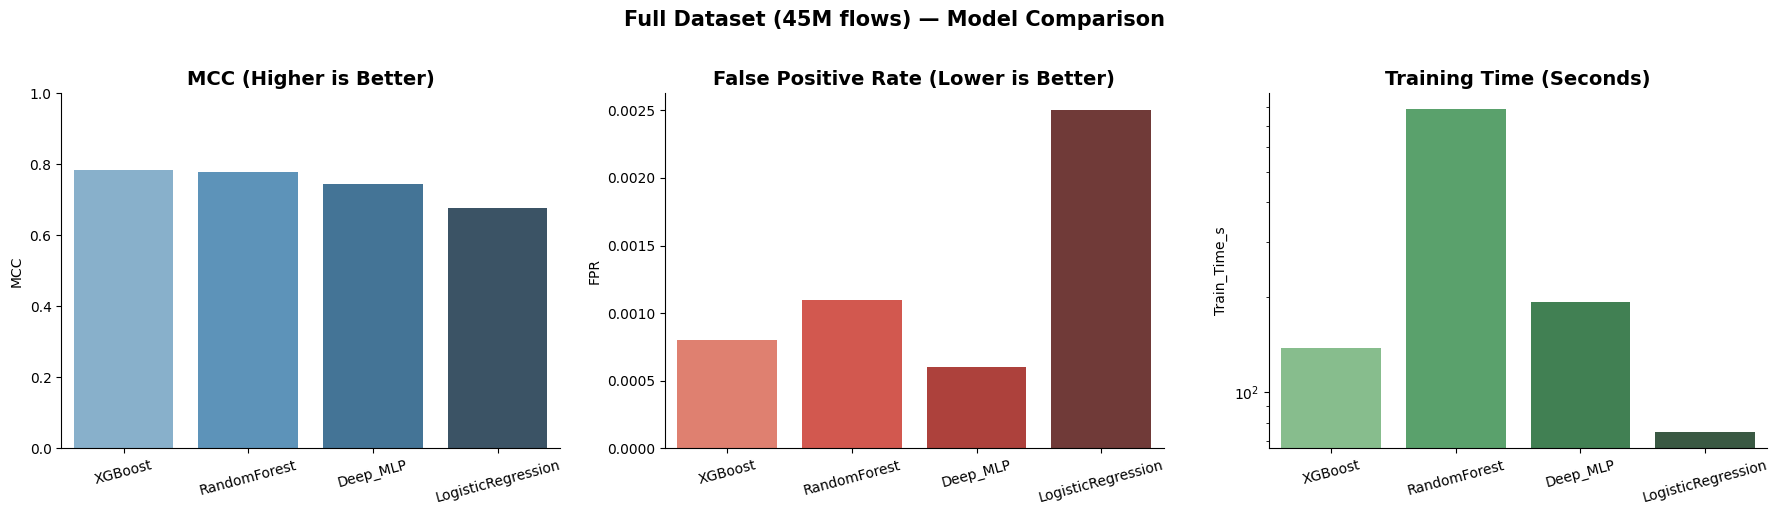

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

data = {
    "Model": ["XGBoost", "RandomForest", "Deep_MLP", "LogisticRegression"],
    "MCC": [0.7851, 0.7796, 0.7441, 0.6777],
    "FPR": [0.0008, 0.0011, 0.0006, 0.0025],
    "Train_Time_s": [137.8, 787.7, 193.4, 74.5]
}
df = pd.DataFrame(data).set_index("Model")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(x=df.index, y="MCC", data=df, ax=axes[0], palette="Blues_d")
axes[0].set_title("MCC (Higher is Better)", fontweight="bold", fontsize=14)
axes[0].set_ylim(0, 1.0)

sns.barplot(x=df.index, y="FPR", data=df, ax=axes[1], palette="Reds_d")
axes[1].set_title("False Positive Rate (Lower is Better)", fontweight="bold", fontsize=14)

sns.barplot(x=df.index, y="Train_Time_s", data=df, ax=axes[2], palette="Greens_d")
axes[2].set_title("Training Time (Seconds)", fontweight="bold", fontsize=14)
axes[2].set_yscale("log")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle("Full Dataset (45M flows) — Model Comparison", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("/content/model_comparison_FULL.png", dpi=300, bbox_inches="tight")
plt.show()